# Credit Risk Prediction Model — Versi 2 (Revisi Metodologi)
**Project-based internship Data Scientist ID/X Partners x Rakamin Academy**

Notebook ini adalah revisi dari `Final_Task_IDX_Partners_Data_Scientist_KhiranaDwicahyo.ipynb`.
Versi pertama melaporkan akurasi **99,3%**, tetapi angka itu ternyata berasal dari *data leakage*,
bukan dari kemampuan model. Di versi ini saya:

1. **Membuktikan** sumber leakage dan mengukur kontribusi masing-masing (bagian 2).
2. **Mendefinisikan ulang target** agar hanya memakai pinjaman yang hasil akhirnya sudah diketahui (bagian 3).
3. **Hanya memakai fitur yang tersedia saat pengajuan pinjaman** (bagian 4).
4. **Memakai split berbasis waktu (out-of-time)** dan memasukkan semua preprocessing serta SMOTE ke dalam pipeline (bagian 5–6).
5. **Mengevaluasi dengan metrik yang lazim di credit scoring** (ROC-AUC, Gini, KS) dan memilih threshold berdasarkan dampak bisnis (bagian 7–8).

| # | Masalah di versi 1 | Dampak | Perbaikan di versi 2 |
|---|---|---|---|
| 1 | SMOTE dijalankan **sebelum** train-test split | Data uji berisi sampel sintetis, tidak mencerminkan data nyata | Split dulu; SMOTE hanya di data latih, di dalam pipeline |
| 2 | Fitur pasca-pencairan (`recoveries`, `total_rec_prncp`, `out_prncp`, `total_pymnt`, `last_pymnt_amnt`, dll.) | Fitur ini "mencatat" hasil pinjaman, sehingga model menyontek jawaban | Hanya fitur yang diketahui saat pengajuan |
| 3 | Target encoding dihitung dari **seluruh** data | Informasi target data uji bocor ke fitur | One-hot encoding di dalam pipeline |
| 4 | Status `Current` dilabeli "tidak berisiko" | ±48% data belum selesai, sehingga hasil akhirnya belum diketahui (label noise) | Hanya pinjaman 36 bulan yang sudah jatuh tempo |
| 5 | `id`, `member_id`, `Unnamed: 0` ikut menjadi fitur | Model belajar dari nomor urut, bukan perilaku peminjam | Dibuang |
| 6 | `fillna(0)` pada `mths_since_last_delinq` | "Tidak pernah menunggak" terbaca sebagai "baru saja menunggak" | Flag + nilai batas yang bermakna |
| 7 | Akurasi pada data seimbang hasil SMOTE | Akurasi menyesatkan pada data tidak seimbang | ROC-AUC, Gini, KS, PR-AUC, analisis threshold |

## 1. Setup & Load Data
Dataset `loan_data_2007_2014.csv` (±240 MB) tidak disimpan di repositori karena melebihi batas ukuran file GitHub.
Letakkan file tersebut di folder `data/` sebelum menjalankan notebook.

In [1]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, confusion_matrix,
                             accuracy_score, precision_score, recall_score, brier_score_loss)
from sklearn.calibration import calibration_curve
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
import xgboost as xgb

RANDOM_STATE = 42
DATA_PATH = Path('../data/loan_data_2007_2014.csv')
OUT_DIR = Path('../outputs/v2')
OUT_DIR.mkdir(parents=True, exist_ok=True)

# gaya grafik: garis tipis, grid samar, warna konsisten (biru = lancar/model, oranye = gagal bayar)
BLUE, ORANGE, AQUA, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c9c8c3', 'axes.labelcolor': '#52514e', 'xtick.color': '#52514e',
    'ytick.color': '#52514e', 'text.color': '#0b0b0b', 'axes.grid': True, 'grid.color': '#e8e7e3',
    'grid.linewidth': 0.8, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.axisbelow': True, 'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'lines.linewidth': 2,
})

raw = pd.read_csv(DATA_PATH, low_memory=False)
print(raw.shape)

(466285, 75)


## 2. Audit: dari mana akurasi 99% berasal?

### 2.1 Fitur `recoveries` hanya bernilai > 0 pada pinjaman Charged Off
`recoveries` adalah uang yang berhasil ditagih **setelah** pinjaman dihapusbukukan. Nilainya baru ada setelah gagal bayar terjadi,
jadi fitur ini tidak mungkin diketahui saat pengajuan. Tidak heran fitur ini menjadi fitur terpenting di versi 1.

In [2]:
audit = raw[~raw['loan_status'].str.startswith('Does not meet')]
post_cols = ['recoveries', 'collection_recovery_fee', 'out_prncp', 'total_rec_late_fee']
(audit.groupby('loan_status')[post_cols]
      .agg(lambda s: (s > 0).mean())
      .rename(columns=lambda c: f'% {c} > 0')
      .mul(100).round(1))

,% recoveries > 0,% collection_recovery_fee > 0,% out_prncp > 0,% total_rec_late_fee > 0
loan_status,,,,
Charged Off,56.2,53.5,0.0,8.7
Current,0.0,0.0,100.0,1.1
Default,0.0,0.0,99.9,8.2
Fully Paid,0.0,0.0,0.0,1.4
In Grace Period,0.0,0.0,99.8,12.1
Late (16-30 days),0.0,0.0,100.0,12.5
Late (31-120 days),0.0,0.0,100.0,14.9


Polanya jelas: `recoveries > 0` **hanya** muncul pada Charged Off, sedangkan `out_prncp > 0` (sisa pokok) ada pada semua pinjaman
yang masih berjalan. Dengan kombinasi fitur pembayaran ini, model bisa "membaca" status pinjaman secara langsung.

### 2.2 Status `Current` belum punya hasil akhir
Data ini adalah *snapshot* per awal 2016 (`last_pymnt_d` terakhir = Jan-2016). Pinjaman yang dicairkan tahun 2013–2014 sebagian besar
masih `Current`: kita belum tahu apakah pinjaman tersebut akan lunas atau macet. Melabelinya sebagai "tidak berisiko" membuat target menjadi bias.

In [3]:
audit_issue = pd.to_datetime(audit['issue_d'], format='%b-%y')
status_by_year = pd.crosstab(audit_issue.dt.year, audit['loan_status'], normalize='index').mul(100)
status_by_year[['Fully Paid', 'Charged Off', 'Current']].round(1)

loan_status,Fully Paid,Charged Off,Current
issue_d,,,
2007,82.1,17.9,0.0
2008,84.2,15.8,0.0
2009,87.4,12.6,0.0
2010,87.0,12.9,0.1
2011,75.8,14.8,9.0
2012,77.7,15.1,6.5
2013,41.9,11.0,44.7
2014,23.2,5.9,67.3


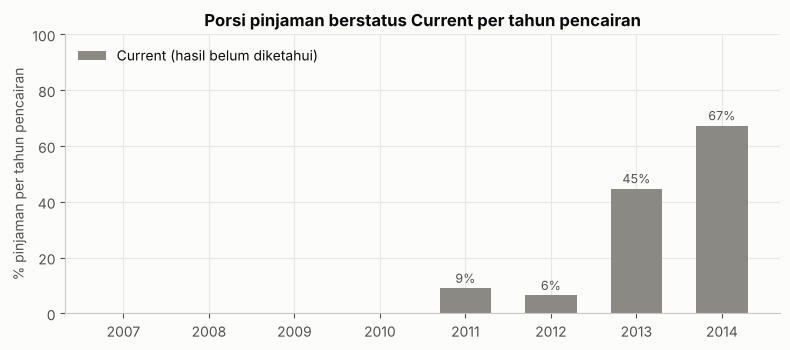

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
yrs = status_by_year.index.astype(str)
ax.bar(yrs, status_by_year['Current'], color=GREY, width=0.6, label='Current (hasil belum diketahui)')
ax.set_ylabel('% pinjaman per tahun pencairan')
ax.set_title('Porsi pinjaman berstatus Current per tahun pencairan')
ax.set_ylim(0, 100)
for x, v in zip(yrs, status_by_year['Current']):
    if v > 1:
        ax.text(x, v + 2, f'{v:.0f}%', ha='center', color='#52514e', fontsize=9)
ax.legend(frameon=False, loc='upper left')
plt.tight_layout(); plt.savefig(OUT_DIR / '01_current_share_by_vintage.png', dpi=150); plt.show()

### 2.3 Eksperimen ablation: kontribusi tiap kesalahan
Saya menjalankan ulang pipeline versi 1, lalu memperbaiki kesalahannya satu per satu. Model yang dipakai sama (XGBoost, 100 trees)
agar perbedaan hasil murni berasal dari metodologi.

- **A — Pipeline versi 1:** target encoding di seluruh data, `fillna(0)`, SMOTE sebelum split.
- **B — Split dulu:** encoding dan SMOTE hanya dihitung dari data latih. Fitur pasca-pencairan masih dipakai.
- **C — Buang fitur pasca-pencairan + ID:** sama seperti B, tetapi hanya fitur yang tersedia saat pengajuan.

In [5]:
def original_prep(df):
    """Replikasi langkah preprocessing versi 1 (untuk perbandingan saja)."""
    df = df.copy()
    df = df.drop(['addr_state', 'desc', 'emp_title', 'title', 'url', 'zip_code'], axis=1)
    df = df.dropna(axis=1, how='all').drop(['pymnt_plan'], axis=1)
    df = df[~df['loan_status'].str.startswith('Does not meet')]
    df['dti_encoded'] = pd.cut(df['dti'], [-np.inf, 10.9999, 30, np.inf], labels=[0, 1, 2]).astype(int)
    df['risk_category'] = (~df['loan_status'].isin(['Fully Paid', 'Current', 'In Grace Period'])).astype(int)
    df['emp_length'] = df['emp_length'].str.extract(r'(\d+)').astype(float)
    for c in ['term', 'grade', 'sub_grade']:
        df[c] = LabelEncoder().fit_transform(df[c])
    return df

V1_NOMINAL = ['purpose', 'verification_status', 'home_ownership', 'application_type', 'initial_list_status']
V1_DROP = ['loan_status', 'risk_category', 'sub_grade', 'dti', 'issue_d', 'earliest_cr_line',
           'last_pymnt_d', 'next_pymnt_d', 'last_credit_pull_d']
POST_ORIGINATION = ['out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp',
                    'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_amnt']
ID_COLS = ['Unnamed: 0', 'id', 'member_id']

def xgb_v1():
    return xgb.XGBClassifier(n_estimators=100, eval_metric='logloss', tree_method='hist',
                             n_jobs=-1, random_state=RANDOM_STATE)

def score_at_05(name, model, X_test, y_test):
    p = model.predict_proba(X_test)[:, 1]
    pred = (p >= 0.5).astype(int)
    return {'Skenario': name,
            'Data uji': 'sintetis (SMOTE)' if name.startswith('A') else 'asli',
            'Accuracy': accuracy_score(y_test, pred),
            'Precision (berisiko)': precision_score(y_test, pred, zero_division=0),
            'Recall (berisiko)': recall_score(y_test, pred),
            'ROC-AUC': roc_auc_score(y_test, p)}

v1 = original_prep(raw)
y_v1 = v1['risk_category']
ablation = []

# A: pipeline versi 1
dA = v1.copy()
for c in V1_NOMINAL:
    dA[c] = dA[c].map(dA.groupby(c)['risk_category'].mean())
XA = dA.drop(columns=V1_DROP).fillna(0)
XA_s, yA_s = SMOTE(random_state=12, sampling_strategy=1).fit_resample(XA, y_v1)
Xtr, Xte, ytr, yte = train_test_split(XA_s, yA_s, test_size=0.2, random_state=RANDOM_STATE, stratify=yA_s)
ablation.append(score_at_05('A. Pipeline versi 1', xgb_v1().fit(Xtr, ytr), Xte, yte))

# B: split dulu, encoding + SMOTE hanya di data latih
tr, te, ytr, yte = train_test_split(v1, y_v1, test_size=0.2, random_state=RANDOM_STATE, stratify=y_v1)
tr, te = tr.copy(), te.copy()
for c in V1_NOMINAL:
    mapping = tr.groupby(c)['risk_category'].mean()
    tr[c], te[c] = tr[c].map(mapping), te[c].map(mapping)
XB_tr, XB_te = tr.drop(columns=V1_DROP).fillna(0), te.drop(columns=V1_DROP).fillna(0)
Xs, ys = SMOTE(random_state=12).fit_resample(XB_tr, ytr)
ablation.append(score_at_05('B. + SMOTE setelah split', xgb_v1().fit(Xs, ys), XB_te, yte))

# C: + buang fitur pasca-pencairan dan ID
XC_tr, XC_te = XB_tr.drop(columns=POST_ORIGINATION + ID_COLS), XB_te.drop(columns=POST_ORIGINATION + ID_COLS)
Xs, ys = SMOTE(random_state=12).fit_resample(XC_tr, ytr)
ablation.append(score_at_05('C. + tanpa fitur pasca-pencairan', xgb_v1().fit(Xs, ys), XC_te, yte))

ablation_df = pd.DataFrame(ablation).set_index('Skenario')
ablation_df.round(3)

,Data uji,Accuracy,Precision (berisiko),Recall (berisiko),ROC-AUC
Skenario,,,,,
A. Pipeline versi 1,sintetis (SMOTE),0.993,1.000,0.986,0.999
B. + SMOTE setelah split,asli,0.988,0.995,0.896,0.995
C. + tanpa fitur pasca-pencairan,asli,0.889,0.416,0.004,0.691


**Interpretasi:**
- **A → B:** memindahkan SMOTE ke setelah split hampir tidak mengubah AUC, karena sumber bocoran yang jauh lebih besar adalah **fitur pasca-pencairan**.
- **B → C:** begitu fitur pasca-pencairan dibuang, ROC-AUC turun dari ±0,99 ke ±0,69. Inilah kemampuan prediksi yang **sebenarnya**.
- Di skenario C, akurasi ±89% hanya setara dengan menebak "semua tidak berisiko" (base rate). Recall kelas berisiko pada threshold 0,5 hampir 0.
  Ini bukti bahwa **akurasi bukan metrik yang tepat** untuk kasus ini.

Skenario C masih memakai target lama (status `Current` = tidak berisiko). Bagian berikutnya memperbaiki target tersebut.

In [6]:
del v1, dA, XA, XA_s, yA_s, tr, te, XB_tr, XB_te, XC_tr, XC_te, Xs, ys, Xtr, Xte

## 3. Definisi Target Baru
Agar label benar-benar mencerminkan hasil akhir pinjaman, saya hanya memakai pinjaman yang **sudah melewati masa tenornya** pada tanggal snapshot (Jan-2016):

- **Tenor 36 bulan** yang dicairkan **2007–2012**. Pinjaman 60 bulan yang sudah jatuh tempo hanya berasal dari tahun 2010,
  jadi saya keluarkan agar populasi konsisten dan tidak tercampur efek tenor.
- Status `Does not meet the credit policy` tetap dikeluarkan, sama seperti versi 1.
- **Target:** `1` = Charged Off / Default / Late (31–120 hari), `0` = Fully Paid.
  Sisa status yang masih ambigu setelah jatuh tempo (Current, In Grace Period, Late 16–30) jumlahnya sangat kecil dan dikeluarkan.

In [7]:
df = raw.copy()
df['issue_d'] = pd.to_datetime(df['issue_d'], format='%b-%y')
SNAPSHOT = pd.Timestamp('2016-01-01')

cohort = df[(df['term'].str.strip() == '36 months')
            & (df['issue_d'] + pd.DateOffset(months=36) < SNAPSHOT)
            & (~df['loan_status'].str.startswith('Does not meet'))].copy()

BAD = ['Charged Off', 'Default', 'Late (31-120 days)']
print(cohort['loan_status'].value_counts(), '\n')
cohort = cohort[cohort['loan_status'].isin(BAD + ['Fully Paid'])].copy()
cohort['target'] = cohort['loan_status'].isin(BAD).astype(int)

print(f'Jumlah pinjaman: {len(cohort):,}')
print(f'Bad rate      : {cohort["target"].mean():.2%}')
print('Periode pencairan:', cohort['issue_d'].min().date(), 's/d', cohort['issue_d'].max().date())

loan_status
Fully Paid            63357
Charged Off            9071
Late (31-120 days)       81
Current                  33
Default                  12
In Grace Period           6
Late (16-30 days)         6
Name: count, dtype: int64 

Jumlah pinjaman: 72,521
Bad rate      : 12.64%
Periode pencairan: 2007-06-01 s/d 2012-12-01


## 4. Fitur: hanya yang tersedia saat pengajuan
Setiap fitur saya cek dengan satu pertanyaan: **"Apakah nilai ini sudah diketahui saat pinjaman diajukan?"**

| Kelompok | Fitur | Keputusan |
|---|---|---|
| Data pengajuan | `loan_amnt`, `int_rate`, `installment`, `sub_grade`, `purpose`, `emp_length`, `home_ownership`, `annual_inc`, `verification_status`, `dti` | Dipakai |
| Riwayat kredit (biro kredit) | `delinq_2yrs`, `inq_last_6mths`, `open_acc`, `pub_rec`, `revol_bal`, `revol_util`, `total_acc`, `mths_since_last_delinq`, `mths_since_last_record`, `earliest_cr_line` | Dipakai |
| Pembayaran/penagihan | `total_pymnt`, `total_rec_*`, `recoveries`, `out_prncp`, `last_pymnt_*`, `next_pymnt_d`, `last_credit_pull_d` | **Dibuang** (pasca-pencairan) |
| Identitas | `id`, `member_id`, `Unnamed: 0`, `url` | **Dibuang** |
| Kosong sebelum 2012 | `tot_cur_bal`, `tot_coll_amt`, `total_rev_hi_lim`, `mths_since_last_major_derog` | **Dibuang** (pola missing berubah menurut waktu) |
| Konstan / berubah definisi | `policy_code`, `application_type`, `initial_list_status` (nilai `w` baru muncul 2012), `term` | **Dibuang** |
| Teks bebas / wilayah | `desc`, `title`, `emp_title`, `zip_code`, `addr_state` | Dibuang (di luar cakupan) |

**Catatan:** `int_rate` dan `sub_grade` adalah hasil penilaian risiko Lending Club sendiri, tetapi nilainya sudah diketahui saat pengajuan, sehingga sah dipakai.

In [8]:
def build_features(d):
    out = pd.DataFrame(index=d.index)
    out['loan_amnt'] = d['loan_amnt']
    out['int_rate'] = d['int_rate']
    out['installment'] = d['installment']
    out['sub_grade_num'] = d['sub_grade'].map({f'{g}{n}': i * 5 + n for i, g in enumerate('ABCDEFG') for n in range(1, 6)})

    emp = d['emp_length'].str.extract(r'(\d+)')[0].astype(float)
    emp[d['emp_length'].str.strip().eq('< 1 year').fillna(False).astype(bool)] = 0   # versi 1 keliru membaca '< 1 year' sebagai 1
    out['emp_length_yrs'] = emp

    out['log_annual_inc'] = np.log1p(d['annual_inc'])
    out['loan_to_income'] = d['loan_amnt'] / d['annual_inc'].replace(0, np.nan)
    out['installment_to_income'] = d['installment'] * 12 / d['annual_inc'].replace(0, np.nan)
    out['dti'] = d['dti']

    for c in ['delinq_2yrs', 'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_util', 'total_acc',
              'collections_12_mths_ex_med', 'acc_now_delinq']:
        out[c] = d[c]
    out['log_revol_bal'] = np.log1p(d['revol_bal'])

    # NaN pada mths_since_* artinya "tidak pernah" -> flag + nilai batas 120 bulan (bukan 0)
    for c, flag in [('mths_since_last_delinq', 'ever_delinq'), ('mths_since_last_record', 'ever_public_record')]:
        out[flag] = d[c].notna().astype(int)
        out[c] = d[c].clip(upper=120).fillna(120)

    # panjang riwayat kredit; '%y' membaca '65' sebagai 2065, jadi tanggal di masa depan dikurangi 100 tahun
    ecl = pd.to_datetime(d['earliest_cr_line'], format='%b-%y')
    ecl = ecl.where(ecl <= d['issue_d'], ecl - pd.DateOffset(years=100))
    out['credit_hist_months'] = (d['issue_d'] - ecl).dt.days / 30.44

    out['home_ownership'] = d['home_ownership'].replace({'NONE': 'OTHER', 'ANY': 'OTHER'})
    out['verification_status'] = d['verification_status']
    out['purpose'] = d['purpose']
    return out

X_all = build_features(cohort)
y_all = cohort['target']
CATEGORICAL = ['home_ownership', 'verification_status', 'purpose']
NUMERIC = [c for c in X_all.columns if c not in CATEGORICAL]
print(X_all.shape)
X_all.describe().T.round(2)

(72521, 26)


,count,mean,std,min,25%,50%,75%,max
loan_amnt,72521.0,10842.02,6863.13,500.00,6000.00,10000.00,14400.00,35000.00
int_rate,72521.0,11.97,3.66,5.42,8.90,12.12,14.33,24.89
installment,72521.0,360.76,234.87,15.69,188.43,316.99,470.75,1388.45
sub_grade_num,72521.0,9.24,5.31,1.00,5.00,9.00,12.00,35.00
emp_length_yrs,69985.0,5.27,3.57,0.00,2.00,5.00,10.00,10.00
log_annual_inc,72521.0,10.96,0.54,8.29,10.60,10.95,11.29,15.78
loan_to_income,72521.0,0.19,0.11,0.00,0.10,0.17,0.25,0.83
installment_to_income,72521.0,0.07,0.04,0.00,0.04,0.07,0.10,0.32
dti,72521.0,15.04,7.44,0.00,9.42,14.86,20.40,34.99
delinq_2yrs,72521.0,0.18,0.58,0.00,0.00,0.00,0.00,18.00


## 5. Split Out-of-Time
Di dunia nyata, model dilatih dengan data masa lalu lalu dipakai untuk pinjaman baru. Karena itu data uji diambil dari periode **setelah** data latih:

- **Train:** pinjaman dicairkan Jun-2007 s/d Jun-2012
- **Test (out-of-time):** pinjaman dicairkan Jul-2012 s/d Des-2012

Semua keputusan model (pemilihan algoritma, balancing, threshold) dibuat **hanya** dari data latih dengan cross-validation.
Data uji dipakai sekali di akhir.

In [9]:
CUTOFF = pd.Timestamp('2012-07-01')
is_train = cohort['issue_d'] < CUTOFF
X_train, y_train = X_all[is_train], y_all[is_train]
X_test, y_test = X_all[~is_train], y_all[~is_train]

pd.DataFrame({'Jumlah': [len(X_train), len(X_test)],
              'Bad rate': [y_train.mean(), y_test.mean()]},
             index=['Train (≤ Jun-2012)', 'Test (Jul–Des 2012)']).style.format({'Jumlah': '{:,}', 'Bad rate': '{:.2%}'})

,Jumlah,Bad rate
Train (≤ Jun-2012),"44,063",12.01%
Test (Jul–Des 2012),"28,458",13.61%


## 6. Pipeline & Perbandingan Model (Cross-Validation pada Data Latih)
Seluruh preprocessing (imputasi, scaling, one-hot) dan SMOTE berada **di dalam pipeline**. Dengan begitu, di setiap fold
cross-validation keduanya hanya "belajar" dari bagian data latih fold tersebut.

Saya membandingkan tiga cara menangani data tidak seimbang: tanpa balancing, class weight, dan SMOTE.

In [10]:
def make_preprocessor(scale=True):
    num_steps = [('impute', SimpleImputer(strategy='median'))]
    if scale:
        num_steps.append(('scale', StandardScaler()))
    return ColumnTransformer([
        ('num', Pipeline(num_steps), NUMERIC),
        ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=50, sparse_output=False), CATEGORICAL),
    ], verbose_feature_names_out=False)

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
XGB_PARAMS = dict(n_estimators=400, learning_rate=0.03, max_depth=4, min_child_weight=10, subsample=0.8,
                  colsample_bytree=0.8, reg_lambda=5, eval_metric='logloss', tree_method='hist',
                  n_jobs=-1, random_state=RANDOM_STATE)

candidates = {
    'Logistic Regression': Pipeline([('prep', make_preprocessor()), ('model', LogisticRegression(max_iter=2000, C=0.5))]),
    'Logistic Regression + class_weight': Pipeline([('prep', make_preprocessor()),
        ('model', LogisticRegression(max_iter=2000, C=0.5, class_weight='balanced'))]),
    'Logistic Regression + SMOTE': ImbPipeline([('prep', make_preprocessor()), ('smote', SMOTE(random_state=RANDOM_STATE)),
        ('model', LogisticRegression(max_iter=2000, C=0.5))]),
    'Random Forest': Pipeline([('prep', make_preprocessor(scale=False)),
        ('model', RandomForestClassifier(n_estimators=300, min_samples_leaf=50, max_features='sqrt',
                                         n_jobs=-1, random_state=RANDOM_STATE))]),
    'XGBoost': Pipeline([('prep', make_preprocessor(scale=False)), ('model', xgb.XGBClassifier(**XGB_PARAMS))]),
    'XGBoost + scale_pos_weight': Pipeline([('prep', make_preprocessor(scale=False)),
        ('model', xgb.XGBClassifier(**XGB_PARAMS, scale_pos_weight=pos_weight))]),
    'XGBoost + SMOTE': ImbPipeline([('prep', make_preprocessor(scale=False)), ('smote', SMOTE(random_state=RANDOM_STATE)),
        ('model', xgb.XGBClassifier(**XGB_PARAMS))]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, pipe in candidates.items():
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=['roc_auc', 'average_precision', 'neg_brier_score'])
    cv_rows.append({'Model': name,
                    'ROC-AUC': s['test_roc_auc'].mean(), 'ROC-AUC (std)': s['test_roc_auc'].std(),
                    'PR-AUC': s['test_average_precision'].mean(),
                    'Brier score': -s['test_neg_brier_score'].mean()})
cv_df = pd.DataFrame(cv_rows).set_index('Model').sort_values('ROC-AUC', ascending=False)
cv_df.round(4)

,ROC-AUC,ROC-AUC (std),PR-AUC,Brier score
Model,,,,
XGBoost,0.6792,0.0062,0.2180,0.1010
XGBoost + scale_pos_weight,0.6772,0.0060,0.2173,0.2147
Random Forest,0.6734,0.0093,0.2129,0.1014
Logistic Regression + class_weight,0.6732,0.0052,0.2134,0.2270
Logistic Regression,0.6732,0.0051,0.2137,0.1013
Logistic Regression + SMOTE,0.6677,0.0037,0.2094,0.2279
XGBoost + SMOTE,0.6657,0.0066,0.2048,0.1027


**Temuan dari cross-validation:**
- Perbedaan ROC-AUC antar model kecil (±0,67–0,68). XGBoost hanya sedikit di atas Logistic Regression. Ini wajar untuk data tabular kredit
  yang sinyal utamanya relatif linear (suku bunga/grade, pendapatan, utilisasi kredit).
- **SMOTE dan class weight tidak menaikkan ROC-AUC**, bahkan SMOTE sedikit menurunkannya. Balancing hanya menggeser skor probabilitas, bukan urutan risiko.
- **Brier score memburuk tajam** (±0,10 → ±0,21–0,23) dengan class weight dan Logistic Regression + SMOTE, karena probabilitasnya
  tidak lagi mencerminkan peluang gagal bayar sebenarnya.
- Karena itu, saya memilih **XGBoost tanpa balancing**. Masalah ketidakseimbangan kelas ditangani di tahap **pemilihan threshold** (bagian 8),
  bukan dengan mengubah data.

In [11]:
final_name = 'XGBoost'
final_model = candidates[final_name]
final_model.fit(X_train, y_train)
p_test = final_model.predict_proba(X_test)[:, 1]

# baseline pembanding: Logistic Regression (model yang mudah dijelaskan, gaya scorecard)
lr_model = candidates['Logistic Regression'].fit(X_train, y_train)
p_test_lr = lr_model.predict_proba(X_test)[:, 1]
# baseline paling sederhana: urutkan risiko hanya berdasarkan sub_grade dari Lending Club
p_test_grade = X_test['sub_grade_num']

## 7. Evaluasi pada Data Uji Out-of-Time

In [12]:
def ks_stat(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return np.max(tpr - fpr)

def eval_row(y, p):
    auc = roc_auc_score(y, p)
    return {'ROC-AUC': auc, 'Gini': 2 * auc - 1, 'KS': ks_stat(y, p), 'PR-AUC': average_precision_score(y, p)}

test_df = pd.DataFrame({
    'XGBoost (final)': eval_row(y_test, p_test),
    'Logistic Regression': eval_row(y_test, p_test_lr),
    'Baseline: sub_grade saja': eval_row(y_test, p_test_grade),
}).T
test_df['Brier score'] = [brier_score_loss(y_test, p_test), brier_score_loss(y_test, p_test_lr), np.nan]
print(f'Bad rate data uji: {y_test.mean():.2%}  (PR-AUC model acak = nilai ini)')
test_df.round(4)

Bad rate data uji: 13.61%  (PR-AUC model acak = nilai ini)


,ROC-AUC,Gini,KS,PR-AUC,Brier score
XGBoost (final),0.6562,0.3124,0.2307,0.2169,0.1137
Logistic Regression,0.6527,0.3054,0.2268,0.2130,0.1141
Baseline: sub_grade saja,0.6212,0.2424,0.1768,0.1860,NaN


**Cara membaca:**
- **ROC-AUC 0,656 / Gini 0,31 / KS 0,23** pada data out-of-time. Angka ini realistis untuk dataset Lending Club dengan fitur saat pengajuan saja.
  Memang jauh di bawah 0,99, tetapi justru inilah performa yang jujur.
- AUC di data uji lebih rendah dibanding cross-validation (0,679). Bad rate naik dari 12,0% (train) ke 13,6% (test), jadi populasi peminjam ikut bergeser.
  Penurunan seperti ini wajar pada validasi out-of-time dan menjadi alasan model kredit perlu dimonitor secara berkala.
- **KS** mengukur seberapa jauh model memisahkan distribusi skor peminjam lancar dan gagal bayar. Metrik ini lazim di industri kredit.
- Model mengalahkan baseline "urutkan berdasarkan `sub_grade` saja" (AUC 0,621). Jadi model menambah informasi di luar grade dari Lending Club.

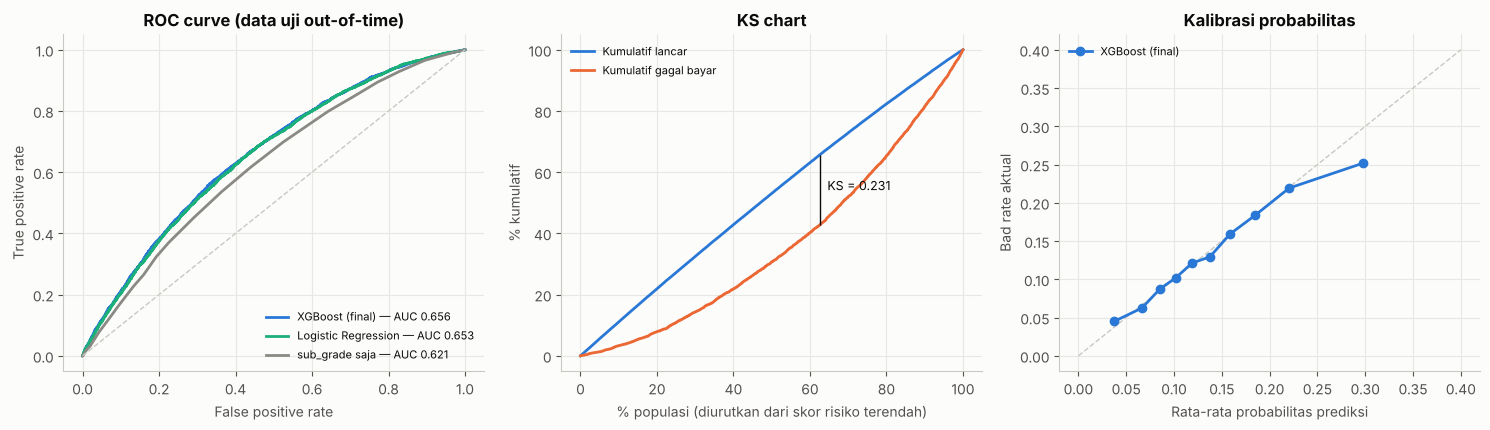

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))

# ROC
for p, lab, col in [(p_test, 'XGBoost (final)', BLUE), (p_test_lr, 'Logistic Regression', AQUA),
                    (p_test_grade, 'sub_grade saja', GREY)]:
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=col, label=f'{lab} — AUC {roc_auc_score(y_test, p):.3f}')
axes[0].plot([0, 1], [0, 1], color='#c9c8c3', linestyle='--', linewidth=1)
axes[0].set(title='ROC curve (data uji out-of-time)', xlabel='False positive rate', ylabel='True positive rate')
axes[0].legend(frameon=False, fontsize=8, loc='lower right')

# KS
order = np.argsort(p_test)
ys = y_test.values[order]
cum_bad = np.cumsum(ys) / ys.sum()
cum_good = np.cumsum(1 - ys) / (1 - ys).sum()
pct = np.arange(1, len(ys) + 1) / len(ys) * 100
k = np.argmax(np.abs(cum_good - cum_bad))
axes[1].plot(pct, cum_good * 100, color=BLUE, label='Kumulatif lancar')
axes[1].plot(pct, cum_bad * 100, color=ORANGE, label='Kumulatif gagal bayar')
axes[1].vlines(pct[k], cum_bad[k] * 100, cum_good[k] * 100, color='#0b0b0b', linewidth=1)
axes[1].text(pct[k] + 2, (cum_bad[k] + cum_good[k]) * 50, f'KS = {abs(cum_good[k] - cum_bad[k]):.3f}', fontsize=9)
axes[1].set(title='KS chart', xlabel='% populasi (diurutkan dari skor risiko terendah)', ylabel='% kumulatif')
axes[1].legend(frameon=False, fontsize=8, loc='upper left')

# Kalibrasi
frac_pos, mean_pred = calibration_curve(y_test, p_test, n_bins=10, strategy='quantile')
axes[2].plot([0, 0.4], [0, 0.4], color='#c9c8c3', linestyle='--', linewidth=1)
axes[2].plot(mean_pred, frac_pos, color=BLUE, marker='o', markersize=6, label='XGBoost (final)')
axes[2].set(title='Kalibrasi probabilitas', xlabel='Rata-rata probabilitas prediksi', ylabel='Bad rate aktual')
axes[2].legend(frameon=False, fontsize=8, loc='upper left')

plt.tight_layout(); plt.savefig(OUT_DIR / '02_roc_ks_calibration.png', dpi=150); plt.show()

Kurva kalibrasi berada dekat garis diagonal, kecuali pada kelompok paling berisiko yang sedikit *overestimate* (prediksi ±0,30 vs aktual ±0,25).
Artinya probabilitas model bisa dibaca sebagai **perkiraan peluang gagal bayar (PD)**. Ini manfaat tidak memakai SMOTE: probabilitas tetap bermakna,
sehingga bisa dipakai untuk perhitungan expected loss atau penentuan harga (pricing).

### Bad rate per decile skor
Ini cara paling mudah menjelaskan model ke pihak bisnis: bandingkan bad rate kelompok skor terendah dan tertinggi.

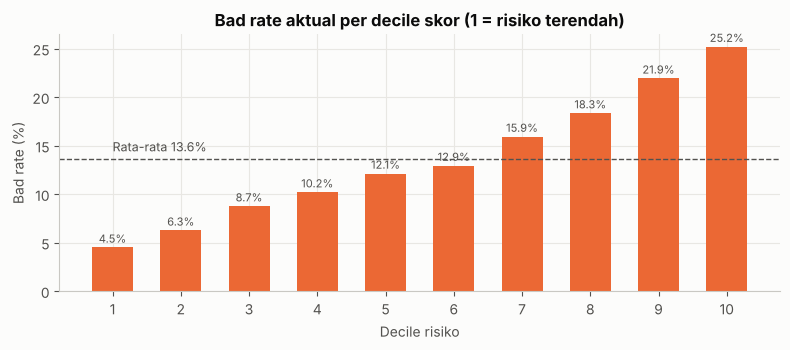

,Jumlah,Rata-rata skor,Bad rate
Decile risiko,,,
1,"2,846",0.037,4.50%
2,"2,846",0.067,6.25%
3,"2,846",0.085,8.75%
4,"2,845",0.102,10.19%
5,"2,846",0.119,12.12%
6,"2,846",0.137,12.93%
7,"2,845",0.159,15.92%
8,"2,846",0.185,18.34%
9,"2,846",0.220,21.93%


In [14]:
dec = pd.DataFrame({'p': p_test, 'y': y_test.values})
dec['Decile risiko'] = pd.qcut(dec['p'].rank(method='first'), 10, labels=range(1, 11))
dec_tbl = dec.groupby('Decile risiko', observed=True).agg(Jumlah=('y', 'size'), Rata_rata_skor=('p', 'mean'),
                                                          Bad_rate=('y', 'mean'))
dec_tbl.columns = ['Jumlah', 'Rata-rata skor', 'Bad rate']

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(dec_tbl.index.astype(str), dec_tbl['Bad rate'] * 100, color=ORANGE, width=0.6)
ax.axhline(y_test.mean() * 100, color='#52514e', linestyle='--', linewidth=1)
ax.text(0, y_test.mean() * 100 + 0.8, f'Rata-rata {y_test.mean():.1%}', fontsize=9, color='#52514e')
for x, v in zip(dec_tbl.index.astype(str), dec_tbl['Bad rate'] * 100):
    ax.text(x, v + 0.5, f'{v:.1f}%', ha='center', fontsize=8, color='#52514e')
ax.set(title='Bad rate aktual per decile skor (1 = risiko terendah)', xlabel='Decile risiko', ylabel='Bad rate (%)')
plt.tight_layout(); plt.savefig(OUT_DIR / '03_bad_rate_by_decile.png', dpi=150); plt.show()
dec_tbl.style.format({'Jumlah': '{:,}', 'Rata-rata skor': '{:.3f}', 'Bad rate': '{:.2%}'})

## 8. Threshold & Dampak Bisnis
Threshold 0,5 tidak punya makna bisnis. Saya mengevaluasi keputusan model dari dua sudut pandang:

1. **Profit:** threshold mana yang memaksimalkan arus kas bersih portofolio?
2. **Risk appetite:** jika perusahaan ingin menekan bad rate, berapa pengajuan yang harus ditolak, dan berapa biayanya?

Arus kas bersih per pinjaman = `total_pymnt - funded_amnt`. Nilainya positif untuk pinjaman lunas (bunga), negatif untuk pinjaman macet.
Kolom ini **tidak dipakai sebagai fitur**, hanya untuk mengevaluasi keputusan, karena memang baru diketahui setelah pinjaman selesai.
Semua threshold dipilih dari prediksi *out-of-fold* pada **data latih**, lalu diterapkan apa adanya ke data uji.
Penyederhanaan: arus kas tidak didiskonto, serta biaya dana dan biaya operasional diabaikan.

In [15]:
cash_train = (cohort.loc[is_train, 'total_pymnt'] - cohort.loc[is_train, 'funded_amnt']).values
cash_test = (cohort.loc[~is_train, 'total_pymnt'] - cohort.loc[~is_train, 'funded_amnt']).values
y_tr, y_te = y_train.values, y_test.values

p_oof = cross_val_predict(candidates[final_name], X_train, y_train, cv=cv, method='predict_proba')[:, 1]

avg_gain = cash_train[y_tr == 0].mean()
avg_loss = -cash_train[y_tr == 1].mean()
breakeven_pd = avg_gain / (avg_gain + avg_loss)
print(f'Rata-rata keuntungan pinjaman lunas : USD {avg_gain:,.0f}')
print(f'Rata-rata kerugian pinjaman macet   : USD {avg_loss:,.0f}')
print(f'Break-even PD                       : {breakeven_pd:.2f}  '
      f'(pinjaman dengan PD di atas nilai ini rata-rata merugi)')
print(f'Porsi data uji dengan PD prediksi > break-even: {(p_test > breakeven_pd).mean():.1%}')

grid = np.round(np.arange(0.05, 0.61, 0.01), 2)
def profit_curve(p, cash):
    return np.array([cash[p < t].sum() for t in grid])
train_profit = profit_curve(p_oof, cash_train)
best_t = float(grid[np.argmax(train_profit)])
print(f'Threshold profit-optimal dari data latih: {best_t:.2f}')

Rata-rata keuntungan pinjaman lunas : USD 1,617
Rata-rata kerugian pinjaman macet   : USD 4,227
Break-even PD                       : 0.28  (pinjaman dengan PD di atas nilai ini rata-rata merugi)
Porsi data uji dengan PD prediksi > break-even: 5.6%
Threshold profit-optimal dari data latih: 0.35


In [16]:
def decision_summary(y, p, cash, t):
    approve = p < t
    return {'Threshold': t, 'Approval rate': approve.mean(), 'Bad rate disetujui': y[approve].mean(),
            'Gagal bayar tertolak (recall)': 1 - y[approve].sum() / y.sum(),
            'Arus kas bersih (USD juta)': cash[approve].sum() / 1e6}

policies = {'Setujui semua (tanpa model)': np.inf, f'Profit-optimal (PD < {best_t:.2f})': best_t}
for reject_pct in [5, 10, 20]:
    policies[f'Cutoff {reject_pct}% teratas (data latih)'] = float(np.quantile(p_oof, 1 - reject_pct / 100))

biz = pd.DataFrame([{'Kebijakan': k, **decision_summary(y_te, p_test, cash_test, t)} for k, t in policies.items()]).set_index('Kebijakan')
base_cash = biz['Arus kas bersih (USD juta)'].iloc[0]
biz['Selisih arus kas vs setujui semua'] = biz['Arus kas bersih (USD juta)'] / base_cash - 1
biz.style.format({'Threshold': '{:.3f}', 'Approval rate': '{:.1%}', 'Bad rate disetujui': '{:.2%}',
                  'Gagal bayar tertolak (recall)': '{:.1%}', 'Arus kas bersih (USD juta)': '{:.2f}',
                  'Selisih arus kas vs setujui semua': '{:+.1%}'})

,Threshold,Approval rate,Bad rate disetujui,Gagal bayar tertolak (recall),Arus kas bersih (USD juta),Selisih arus kas vs setujui semua
Kebijakan,,,,,,
Setujui semua (tanpa model),inf,100.0%,13.61%,0.0%,35.82,+0.0%
Profit-optimal (PD < 0.35),0.350,98.6%,13.37%,3.2%,35.60,-0.6%
Cutoff 5% teratas (data latih),0.255,91.6%,12.48%,16.1%,33.81,-5.6%
Cutoff 10% teratas (data latih),0.214,83.6%,11.57%,28.9%,31.12,-13.1%
Cutoff 20% teratas (data latih),0.171,70.2%,10.13%,47.7%,26.51,-26.0%


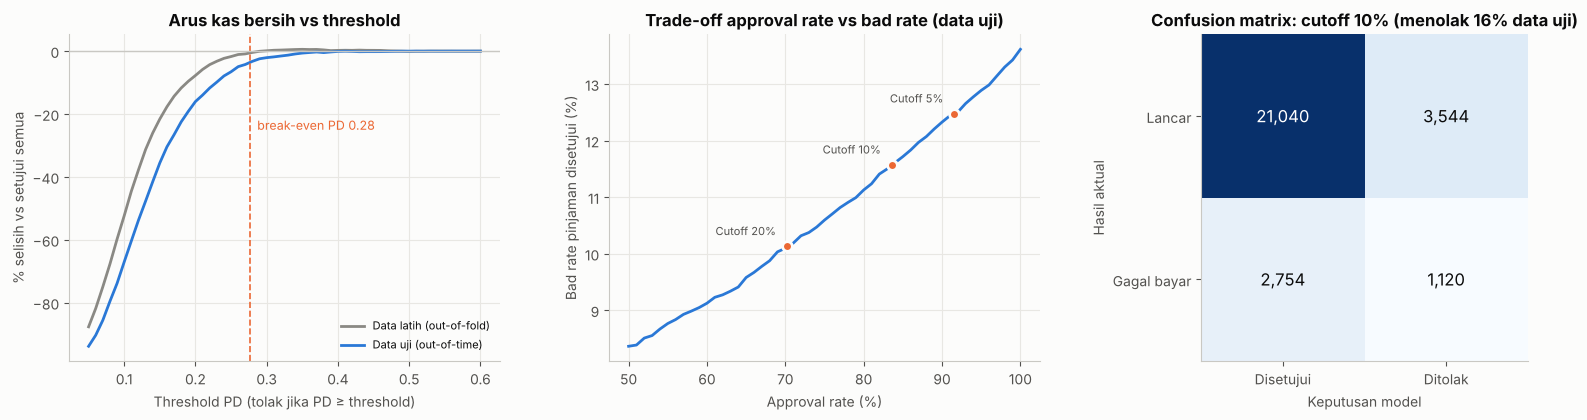

In [17]:
risk_t = policies['Cutoff 10% teratas (data latih)']
test_profit = profit_curve(p_test, cash_test)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))

axes[0].plot(grid, (train_profit / train_profit[-1] - 1) * 100, color=GREY, label='Data latih (out-of-fold)')
axes[0].plot(grid, (test_profit / test_profit[-1] - 1) * 100, color=BLUE, label='Data uji (out-of-time)')
axes[0].axvline(breakeven_pd, color=ORANGE, linewidth=1.2, linestyle='--')
axes[0].text(breakeven_pd + 0.01, -25, f'break-even PD {breakeven_pd:.2f}', color=ORANGE, fontsize=9)
axes[0].axhline(0, color='#c9c8c3', linewidth=1)
axes[0].set(title='Arus kas bersih vs threshold', xlabel='Threshold PD (tolak jika PD ≥ threshold)',
            ylabel='% selisih vs setujui semua')
axes[0].legend(frameon=False, fontsize=8, loc='lower right')

qs = np.linspace(0.5, 1, 51)
appr, badr = [], []
for q in qs:
    t = np.quantile(p_test, q)
    m = p_test <= t
    appr.append(m.mean() * 100); badr.append(y_te[m].mean() * 100)
axes[1].plot(appr, badr, color=BLUE)
for k, t in list(policies.items())[2:]:
    r = biz.loc[k]
    axes[1].plot(r['Approval rate'] * 100, r['Bad rate disetujui'] * 100, 'o', color=ORANGE, markersize=7,
                 markeredgecolor='#fcfcfb', markeredgewidth=2)
    axes[1].annotate(k.replace(' teratas (data latih)', ''), (r['Approval rate'] * 100, r['Bad rate disetujui'] * 100),
                     textcoords='offset points', xytext=(-8, 8), ha='right', fontsize=8, color='#52514e')
axes[1].set(title='Trade-off approval rate vs bad rate (data uji)', xlabel='Approval rate (%)', ylabel='Bad rate pinjaman disetujui (%)')

cm = confusion_matrix(y_te, (p_test >= risk_t).astype(int))
axes[2].imshow(cm, cmap='Blues'); axes[2].grid(False)
axes[2].set_xticks([0, 1], ['Disetujui', 'Ditolak']); axes[2].set_yticks([0, 1], ['Lancar', 'Gagal bayar'])
for i in range(2):
    for j in range(2):
        axes[2].text(j, i, f'{cm[i, j]:,}', ha='center', va='center', fontsize=12,
                     color='white' if cm[i, j] > cm.max() / 2 else '#0b0b0b')
axes[2].set(title=f'Confusion matrix: cutoff 10% (menolak {(p_test >= risk_t).mean():.0%} data uji)', xlabel='Keputusan model', ylabel='Hasil aktual')
plt.tight_layout(); plt.savefig(OUT_DIR / '04_threshold_business.png', dpi=150); plt.show()

**Temuan bisnis — model ini tidak menaikkan profit lewat penolakan, dan itu temuan yang penting:**

- Data ini berisi pinjaman yang **sudah disetujui dan sudah diberi harga** oleh Lending Club. Peminjam berisiko tinggi sudah dikenai bunga tinggi.
  Dengan rata-rata untung USD 1.617 per pinjaman lunas dan rugi USD 4.227 per pinjaman macet, sebuah pinjaman baru merugi jika PD-nya > 0,28.
  Hanya ±6% pengajuan di data uji yang melewati batas itu.
- Karena itu, threshold profit-optimal (0,35) hanya menolak ±1,4% pengajuan. Arus kas di data uji bahkan sedikit di bawah
  "setujui semua" (−0,6%), jadi praktis setara.
- Jika perusahaan ingin **menekan bad rate** (risk appetite), model bisa melakukannya. Cutoff 10% menurunkan bad rate dari 13,6% ke 11,6%
  dan menangkap ±29% kasus gagal bayar. Biayanya, arus kas turun ±13%, karena sebagian besar yang tertolak adalah peminjam lancar berbunga tinggi.
- Cutoff yang diambil dari persentil data latih menolak lebih banyak di data uji (±16%, bukan 10%), karena skor rata-rata ikut naik di periode uji.
  Ini contoh nyata mengapa distribusi skor perlu dimonitor (misalnya dengan PSI).

Jadi nilai utama model ini adalah **estimasi PD yang terkalibrasi** untuk pricing, expected loss, dan pengendalian risk appetite,
bukan aturan tolak/terima yang otomatis menaikkan profit.

## 9. Interpretasi Model (SHAP)
Nilai SHAP menunjukkan seberapa besar setiap fitur mendorong prediksi naik atau turun untuk tiap peminjam.
Nilai ini dihitung dengan `pred_contribs` bawaan XGBoost (TreeSHAP), sehingga tidak perlu library tambahan.

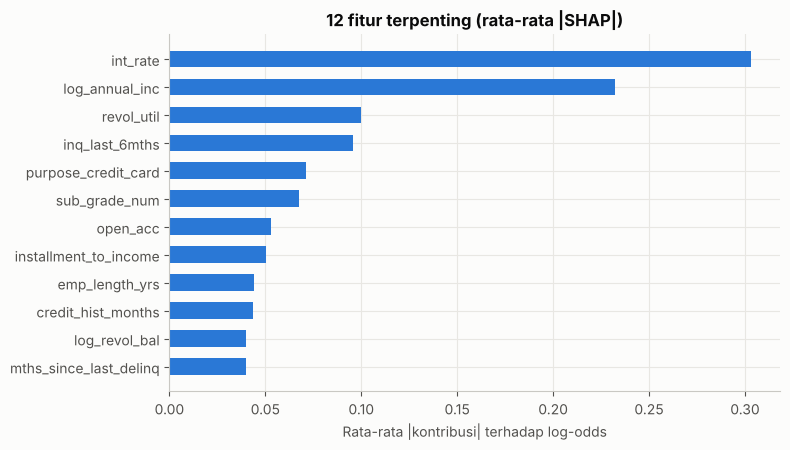

,Rata-rata |SHAP|,Arah (nilai fitur naik → risiko ...)
int_rate,0.3031,naik
log_annual_inc,0.2321,turun
revol_util,0.0999,naik
inq_last_6mths,0.0958,naik
purpose_credit_card,0.0712,turun
sub_grade_num,0.0674,naik


In [18]:
prep = final_model.named_steps['prep']
booster = final_model.named_steps['model'].get_booster()
X_test_t = prep.transform(X_test)
feat_names = prep.get_feature_names_out()
contribs = booster.predict(xgb.DMatrix(X_test_t, feature_names=list(feat_names)), pred_contribs=True)[:, :-1]
shap_imp = pd.Series(np.abs(contribs).mean(axis=0), index=feat_names).sort_values(ascending=False)

top = shap_imp.head(12)[::-1]
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(top.index, top.values, color=BLUE, height=0.6)
ax.set(title='12 fitur terpenting (rata-rata |SHAP|)', xlabel='Rata-rata |kontribusi| terhadap log-odds')
plt.tight_layout(); plt.savefig(OUT_DIR / '05_shap_importance.png', dpi=150); plt.show()

# arah pengaruh: korelasi nilai fitur dengan nilai SHAP-nya
direction = pd.Series({f: np.corrcoef(X_test_t[:, i], contribs[:, i])[0, 1] if X_test_t[:, i].std() > 0 else np.nan
                       for i, f in enumerate(feat_names)})
pd.DataFrame({'Rata-rata |SHAP|': shap_imp.head(6),
              'Arah (nilai fitur naik → risiko ...)': direction[shap_imp.head(6).index]
                  .map(lambda r: 'naik' if r > 0.1 else ('turun' if r < -0.1 else 'tidak monoton'))}).round(4)

Berbeda dengan versi 1 (fitur terpenting: `recoveries`), fitur terpenting sekarang **masuk akal secara bisnis**:
suku bunga (risiko naik), pendapatan tahunan (risiko turun), utilisasi kredit bergulir dan jumlah inquiry kredit 6 bulan terakhir (risiko naik),
serta tujuan pinjaman *credit card* yang cenderung lebih aman. Tabel arah hanya untuk 6 fitur teratas.
Untuk fitur berkontribusi kecil, arah pengaruhnya tidak stabil dan dipengaruhi interaksi antar fitur.

## 10. Simpan Model & Ringkasan Metrik
Pipeline lengkap (preprocessing + model) disimpan agar bisa langsung dipakai di aplikasi, misalnya dashboard Streamlit.

In [19]:
joblib.dump({'pipeline': final_model, 'threshold_profit': best_t, 'threshold_reject_10pct': risk_t,
             'breakeven_pd': float(breakeven_pd), 'features': list(X_all.columns),
             'categorical': CATEGORICAL}, OUT_DIR / 'credit_risk_model_v2.joblib')

summary = {
    'cohort': {'n_loans': int(len(cohort)), 'bad_rate': float(y_all.mean()),
               'train_n': int(len(X_train)), 'test_n': int(len(X_test))},
    'ablation': ablation_df.round(4).reset_index().to_dict(orient='records'),
    'cv_train': cv_df.round(4).reset_index().to_dict(orient='records'),
    'test_out_of_time': test_df.round(4).reset_index().rename(columns={'index': 'Model'}).to_dict(orient='records'),
    'business': biz.round(4).reset_index().to_dict(orient='records'),
    'top_features_shap': shap_imp.head(12).round(4).to_dict(),
}
(OUT_DIR / 'metrics_v2.json').write_text(json.dumps(summary, indent=2, default=float))
print('Tersimpan di', OUT_DIR.resolve())

Tersimpan di /home/claude/work/repo/outputs/v2


## 11. Kesimpulan

1. **Akurasi 99% di versi 1 adalah hasil data leakage.** Kontributor terbesarnya adalah fitur pasca-pencairan (`recoveries`, `total_rec_prncp`, dll.),
   bukan hanya SMOTE yang dijalankan sebelum split. Begitu fitur tersebut dibuang, ROC-AUC turun ke ±0,69.
2. **Dengan target yang benar** (pinjaman yang sudah jatuh tempo), fitur saat pengajuan, dan validasi out-of-time, model XGBoost mencapai
   ROC-AUC 0,656 (Gini 0,31, KS 0,23) dan memisahkan risiko dengan jelas: bad rate decile teratas 25,2% vs decile terendah 4,5%.
3. **SMOTE tidak diperlukan.** SMOTE tidak menaikkan kemampuan model mengurutkan risiko, dan justru merusak kalibrasi probabilitas.
   Ketidakseimbangan kelas lebih tepat ditangani lewat **pemilihan threshold berbasis biaya/keuntungan**.
4. **Dampak bisnis:** karena pinjaman sudah diberi harga sesuai risiko, aturan tolak berbasis profit hampir tidak mengubah arus kas.
   Model paling berguna sebagai estimasi PD (pricing, expected loss) dan untuk mengatur trade-off bad rate vs volume sesuai risk appetite.

### Keterbatasan & pengembangan selanjutnya
- **Bias seleksi:** data hanya berisi pinjaman yang *disetujui*. Pengajuan yang ditolak Lending Club tidak ada di data, sehingga perlu teknik *reject inference* jika model dipakai untuk seluruh pemohon.
- **Cakupan:** hanya tenor 36 bulan, periode 2007–2012. Sudah terlihat pergeseran populasi di periode uji, jadi model perlu dimonitor (misalnya dengan PSI).
- **Perhitungan bisnis disederhanakan:** tanpa diskonto, biaya dana, dan biaya operasional.
- Pengembangan: hyperparameter tuning dengan validasi berbasis waktu, fitur teks (`desc`, `emp_title`), dan scorecard berbasis WoE untuk kebutuhan regulasi.